# Review of model and strategy results

This notebook brings together saved results from the five-fold model comparison, the long-or-cash backtest, the indicator ablation, and the fold robustness review. It reads existing CSV files; it does not fit models or tune settings.

The tables are evidence for review, not dissertation conclusions. The test folds have already been inspected, and transaction-cost values are illustrative per-side scenarios.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

# Keep all inputs and the derived comparison table inside the project.
ROOT = Path.cwd()
RESULTS = ROOT / 'results'
fold_metrics = pd.read_csv(RESULTS / 'advanced_model_fold_metrics.csv')
backtest = pd.read_csv(RESULTS / 'long_or_cash_backtest_summary.csv')
indicator_deltas = pd.read_csv(RESULTS / 'indicator_ablation_deltas.csv')
robustness = pd.read_csv(RESULTS / 'robustness_backtest_stability.csv')
print(f"Loaded {len(fold_metrics)} fold-metric rows and {len(backtest)} cost-scenario backtests.")

Loaded 50 fold-metric rows and 50 cost-scenario backtests.


## Check that the saved tables line up

Before comparing results, check that each ETF has five folds, model rows are unique within each fold, and the backtest includes all five cost scenarios.

In [2]:
# A duplicate here would count the same model/fold more than once in the averages.
assert not fold_metrics.duplicated(['ETF', 'fold', 'model']).any()
assert not backtest.duplicated(['ETF', 'model', 'cost_bps_per_side']).any()
assert set(fold_metrics['ETF']) == {'QQQ', 'SPY'}
assert fold_metrics.groupby('ETF')['fold'].nunique().eq(5).all()
assert sorted(backtest['cost_bps_per_side'].unique()) == [0.0, 1.0, 2.5, 5.0, 10.0]
print('Coverage and uniqueness checks passed.')

Coverage and uniqueness checks passed.


## Predictive performance across folds

The means summarize five chronological test periods. Standard deviation and range show how much accuracy varied between them. ROC-AUC is missing for the two hard-label baselines because they do not provide probability scores.

In [3]:
# Keep fold variation visible rather than reporting only one average score.
predictive_summary = (
    fold_metrics.groupby(['ETF', 'model'], sort=True)
    .agg(
        folds=('fold', 'nunique'),
        mean_accuracy=('accuracy', 'mean'),
        sd_accuracy=('accuracy', 'std'),
        min_accuracy=('accuracy', 'min'),
        max_accuracy=('accuracy', 'max'),
        mean_balanced_accuracy=('balanced_accuracy', 'mean'),
        mean_f1_up=('f1_up', 'mean'),
        mean_roc_auc=('roc_auc', 'mean'),
    )
    .reset_index()
)
predictive_summary.sort_values(['ETF', 'mean_accuracy'], ascending=[True, False])

,ETF,model,folds,mean_accuracy,sd_accuracy,min_accuracy,max_accuracy,mean_balanced_accuracy,mean_f1_up,mean_roc_auc
4,QQQ,XGBoost,5,0.515317,0.010405,0.503675,0.529050,0.513830,0.574276,0.523043
1,QQQ,LSTM,5,0.514181,0.006903,0.507751,0.525869,0.511830,0.599876,0.519153
2,QQQ,Logistic regression,5,0.507456,0.007320,0.497406,0.518024,0.504211,0.622048,0.513531
3,QQQ,Majority baseline,5,0.505541,0.003400,0.500424,0.508647,0.500000,0.671568,NaN
0,QQQ,Direction persistence baseline,5,0.481307,0.014117,0.456743,0.493098,0.481297,0.484014,NaN
9,SPY,XGBoost,5,0.517481,0.011359,0.498436,0.526459,0.516287,0.578313,0.528344
6,SPY,LSTM,5,0.513167,0.013302,0.495725,0.530029,0.512051,0.599367,0.525837
7,SPY,Logistic regression,5,0.513009,0.008676,0.503650,0.522673,0.511335,0.588438,0.519527
8,SPY,Majority baseline,5,0.504164,0.008595,0.494960,0.516381,0.500000,0.670323,NaN
5,SPY,Direction persistence baseline,5,0.478864,0.009820,0.463881,0.489895,0.478834,0.480239,NaN


## Paired comparison with the majority baseline

For each fold, compare each model's accuracy with the majority baseline from the same ETF and test period. Counting positive-fold differences is descriptive; five folds are too few to make this a significance test.

In [4]:
# Pair on ETF and fold so each model is compared with the matching test period.
majority = fold_metrics.loc[
    fold_metrics['model'].eq('Majority baseline'),
    ['ETF', 'fold', 'accuracy', 'balanced_accuracy'],
].rename(columns={
    'accuracy': 'majority_accuracy',
    'balanced_accuracy': 'majority_balanced_accuracy',
})
paired = fold_metrics.merge(
    majority,
    on=['ETF', 'fold'],
    how='left',
    validate='many_to_one',
)
paired['accuracy_delta_vs_majority'] = paired['accuracy'] - paired['majority_accuracy']
paired['balanced_accuracy_delta_vs_majority'] = (
    paired['balanced_accuracy'] - paired['majority_balanced_accuracy']
)
paired_summary = (
    paired.groupby(['ETF', 'model'], sort=True)
    .agg(
        folds=('fold', 'nunique'),
        mean_accuracy_delta=('accuracy_delta_vs_majority', 'mean'),
        folds_above_majority=('accuracy_delta_vs_majority', lambda x: int((x > 0).sum())),
        mean_balanced_accuracy_delta=('balanced_accuracy_delta_vs_majority', 'mean'),
    )
    .reset_index()
)
paired_summary.sort_values(['ETF', 'model'])

,ETF,model,folds,mean_accuracy_delta,folds_above_majority,mean_balanced_accuracy_delta
0,QQQ,Direction persistence baseline,5,-0.024233,0,-0.018703
1,QQQ,LSTM,5,0.008640,5,0.011830
2,QQQ,Logistic regression,5,0.001915,2,0.004211
3,QQQ,Majority baseline,5,0.000000,0,0.000000
4,QQQ,XGBoost,5,0.009776,4,0.013830
5,SPY,Direction persistence baseline,5,-0.025300,0,-0.021166
6,SPY,LSTM,5,0.009003,4,0.012051
7,SPY,Logistic regression,5,0.008845,4,0.011335
8,SPY,Majority baseline,5,0.000000,0,0.000000
9,SPY,XGBoost,5,0.013317,4,0.016287


## Trading performance under the cost scenarios

These are continuous-period backtest summaries over the shared out-of-sample predictions. Costs are applied per side. Returns are hypothetical and depend on the next-bar-open execution assumption. One-way turnover sums absolute changes in the long-or-cash position; entries per session shows how often a position is opened. Costs are applied separately for each side.

In [5]:
# Show all tested cost assumptions so the sensitivity is easy to compare.
strategy_columns = [
    'ETF', 'model', 'cost_bps_per_side', 'net_cumulative_return',
    'maximum_drawdown', 'annualized_daily_sharpe', 'entries_per_session',
    'exposure_fraction', 'one_way_turnover',
]
strategy_summary = backtest[strategy_columns].sort_values(
    ['ETF', 'model', 'cost_bps_per_side']
)
strategy_summary

,ETF,model,cost_bps_per_side,net_cumulative_return,maximum_drawdown,annualized_daily_sharpe,entries_per_session,exposure_fraction,one_way_turnover
5,QQQ,Direction persistence baseline,0.0,-0.213640,-0.214474,-1.614905,13.230603,0.499808,12278.0
6,QQQ,Direction persistence baseline,1.0,-0.769661,-0.769661,-9.728473,13.230603,0.499808,12278.0
7,QQQ,Direction persistence baseline,2.5,-0.963492,-0.963492,-20.564345,13.230603,0.499808,12278.0
8,QQQ,Direction persistence baseline,5.0,-0.998306,-0.998306,-34.653787,13.230603,0.499808,12278.0
9,QQQ,Direction persistence baseline,10.0,-0.999996,-0.999996,-51.248591,13.230603,0.499808,12278.0
20,QQQ,LSTM,0.0,0.165072,-0.065568,1.082548,8.127155,0.709595,7542.0
21,QQQ,LSTM,1.0,-0.451986,-0.452526,-4.123478,8.127155,0.709595,7542.0
22,QQQ,LSTM,2.5,-0.823238,-0.823238,-11.922132,8.127155,0.709595,7542.0
23,QQQ,LSTM,5.0,-0.973195,-0.973195,-23.404675,8.127155,0.709595,7542.0
24,QQQ,LSTM,10.0,-0.999384,-0.999384,-37.245058,8.127155,0.709595,7542.0


### Trading activity by model

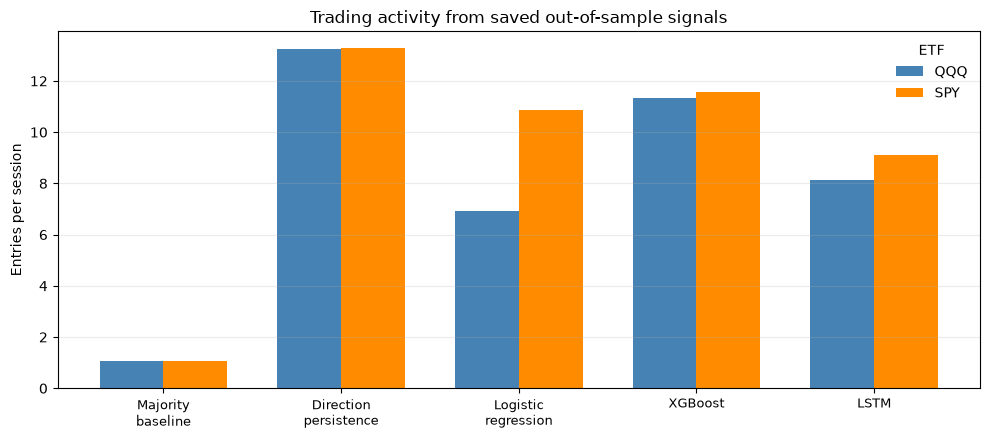

In [6]:
# Use one cost row because cost assumptions do not change the saved signals.
activity = backtest.loc[backtest['cost_bps_per_side'].eq(0.0)]
model_order = [
    'Majority baseline', 'Direction persistence baseline',
    'Logistic regression', 'XGBoost', 'LSTM',
]
label_names = {
    'Majority baseline': 'Majority\nbaseline',
    'Direction persistence baseline': 'Direction\npersistence',
    'Logistic regression': 'Logistic\nregression',
    'XGBoost': 'XGBoost',
    'LSTM': 'LSTM',
}
activity_by_model = activity.pivot(
    index='model', columns='ETF', values='entries_per_session'
).reindex(model_order)
positions = list(range(len(model_order)))
bar_width = 0.36
fig, axis = plt.subplots(figsize=(10, 4.5))
for offset, ticker, color in [
    (-bar_width / 2, 'QQQ', 'steelblue'),
    (bar_width / 2, 'SPY', 'darkorange'),
]:
    axis.bar(
        [position + offset for position in positions],
        activity_by_model[ticker],
        width=bar_width,
        label=ticker,
        color=color,
    )
axis.set_xticks(positions, [label_names[name] for name in model_order], fontsize=9)
axis.set_ylabel('Entries per session')
axis.set_title('Trading activity from saved out-of-sample signals')
axis.legend(title='ETF', frameon=False)
axis.grid(axis='y', alpha=0.25)
fig.tight_layout()
plt.show()


## Join predictive and trading summaries

The joined table places mean fold accuracy beside the continuous-period strategy outcomes. The 0 bp column is a gross reference; 1 bp per side is an illustrative cost case, not a verified execution estimate.

In [7]:
# Normalize model labels only for joining; keep the original labels for display.
predictive_for_join = predictive_summary.copy()
strategy_for_join = backtest.loc[
    backtest['cost_bps_per_side'].isin([0.0, 1.0])
].copy()
predictive_for_join['model_key'] = predictive_for_join['model'].str.strip().str.lower()
strategy_for_join['model_key'] = strategy_for_join['model'].str.strip().str.lower()

comparison = predictive_for_join.merge(
    strategy_for_join,
    on=['ETF', 'model_key'],
    how='inner',
    validate='one_to_many',
    suffixes=('_predictive', '_strategy'),
)
comparison_table = comparison[[
    'ETF', 'model_predictive', 'folds', 'mean_accuracy', 'sd_accuracy',
    'mean_balanced_accuracy', 'mean_f1_up', 'mean_roc_auc',
    'cost_bps_per_side', 'net_cumulative_return', 'maximum_drawdown',
    'annualized_daily_sharpe', 'entries_per_session', 'exposure_fraction',
    'one_way_turnover',
]].sort_values(['ETF', 'model_predictive', 'cost_bps_per_side'])

# Save a compact table that can be reviewed without rerunning this notebook.
comparison_table.to_csv(RESULTS / 'model_strategy_comparison.csv', index=False)
comparison_table

,ETF,model_predictive,folds,mean_accuracy,sd_accuracy,mean_balanced_accuracy,mean_f1_up,mean_roc_auc,cost_bps_per_side,net_cumulative_return,maximum_drawdown,annualized_daily_sharpe,entries_per_session,exposure_fraction,one_way_turnover
0,QQQ,Direction persistence baseline,5,0.481307,0.014117,0.481297,0.484014,NaN,0.0,-0.213640,-0.214474,-1.614905,13.230603,0.499808,12278.0
1,QQQ,Direction persistence baseline,5,0.481307,0.014117,0.481297,0.484014,NaN,1.0,-0.769661,-0.769661,-9.728473,13.230603,0.499808,12278.0
2,QQQ,LSTM,5,0.514181,0.006903,0.511830,0.599876,0.519153,0.0,0.165072,-0.065568,1.082548,8.127155,0.709595,7542.0
3,QQQ,LSTM,5,0.514181,0.006903,0.511830,0.599876,0.519153,1.0,-0.451986,-0.452526,-4.123478,8.127155,0.709595,7542.0
4,QQQ,Logistic regression,5,0.507456,0.007320,0.504211,0.622048,0.513531,0.0,0.073871,-0.077835,0.498398,6.922414,0.799650,6424.0
5,QQQ,Logistic regression,5,0.507456,0.007320,0.504211,0.622048,0.513531,1.0,-0.435132,-0.436168,-3.703547,6.922414,0.799650,6424.0
6,QQQ,Majority baseline,5,0.505541,0.003400,0.500000,0.671568,NaN,0.0,0.059644,-0.096909,0.313251,1.068966,1.000000,992.0
7,QQQ,Majority baseline,5,0.505541,0.003400,0.500000,0.671568,NaN,1.0,-0.040432,-0.111244,-0.117906,1.068966,1.000000,992.0
8,QQQ,XGBoost,5,0.515317,0.010405,0.513830,0.574276,0.523043,0.0,0.371844,-0.062964,2.250617,11.327586,0.634058,10512.0
9,QQQ,XGBoost,5,0.515317,0.010405,0.513830,0.574276,0.523043,1.0,-0.520541,-0.520541,-5.143173,11.327586,0.634058,10512.0


## Indicator ablation: matched-sample changes

The indicator deltas compare base features with base-plus-indicator features on the same smaller, warm-up-complete sample. Do not compare these absolute scores directly with the full-sample model summary above.

In [8]:
# Focus the view on XGBoost while retaining both ETFs and every reported metric.
xgboost_indicator_delta = indicator_deltas.loc[
    indicator_deltas['model'].str.strip().str.lower().eq('xgboost')
].sort_values('ETF')
xgboost_indicator_delta

,ETF,comparison,model,accuracy_indicators,balanced_accuracy_indicators,f1_up_indicators,roc_auc_indicators,accuracy_base,balanced_accuracy_base,f1_up_base,roc_auc_base,accuracy_delta,balanced_accuracy_delta,f1_up_delta,roc_auc_delta
4,QQQ,+ technical indicators minus base,XGBoost,0.512976,0.512039,0.572095,0.518282,0.515427,0.514515,0.574419,0.524460,-0.002451,-0.002476,-0.002324,-0.006177
9,SPY,+ technical indicators minus base,XGBoost,0.514420,0.514845,0.568588,0.526635,0.514657,0.514957,0.571833,0.528657,-0.000237,-0.000113,-0.003245,-0.002022


## Fold-to-fold strategy variation

The robustness returns treat each fold as a separate portfolio that starts and ends flat. They are not compounded together and are not the same calculation as the continuous-period backtest above.

In [9]:
# Use XGBoost as an example and show how many folds were positive at each cost.
xgboost_robustness = robustness.loc[
    robustness['model'].eq('XGBoost'),
    ['ETF', 'cost_bps_per_side', 'folds', 'positive_return_folds',
     'mean_net_cumulative_return', 'minimum_net_cumulative_return',
     'maximum_net_cumulative_return', 'mean_maximum_drawdown'],
].sort_values(['ETF', 'cost_bps_per_side'])
xgboost_robustness

,ETF,cost_bps_per_side,folds,positive_return_folds,mean_net_cumulative_return,minimum_net_cumulative_return,maximum_net_cumulative_return,mean_maximum_drawdown
20,QQQ,0.0,5,5,0.065290,0.057410,0.075726,-0.032046
21,QQQ,1.0,5,0,-0.136680,-0.145962,-0.120511,-0.146879
22,QQQ,2.5,5,0,-0.370131,-0.386784,-0.349860,-0.371386
23,QQQ,5.0,5,0,-0.627518,-0.646985,-0.607122,-0.627518
24,QQQ,10.0,5,0,-0.869674,-0.883058,-0.856585,-0.869674
45,SPY,0.0,5,5,0.050645,0.005763,0.090743,-0.032222
46,SPY,1.0,5,0,-0.152494,-0.187624,-0.121153,-0.158312
47,SPY,2.5,5,0,-0.385903,-0.422098,-0.353640,-0.385903
48,SPY,5.0,5,0,-0.640886,-0.672434,-0.612714,-0.640886
49,SPY,10.0,5,0,-0.877015,-0.894803,-0.861011,-0.877015


## Signal-to-execution gap

The horizontal axis is each model's mean accuracy lift over the majority baseline, in percentage points. The vertical axis is its full-period net strategy return at the illustrative 1 bp-per-side cost. Each point represents one ETF/model combination. This makes it easy to ask whether a predictive lift survives the trading assumption; accuracy and return still measure different things.

In [10]:
# Put the zero-cost and 1 bp results side by side for each ETF/model.
returns_by_cost = comparison.pivot(
    index=['ETF', 'model_predictive', 'mean_accuracy'],
    columns='cost_bps_per_side',
    values='net_cumulative_return',
).reset_index()
returns_by_cost = returns_by_cost.rename(columns={
    0.0: 'net_return_0bp',
    1.0: 'net_return_1bp',
})

# Compare each model's average fold accuracy with its ETF's majority baseline.
majority_accuracy = predictive_summary.loc[
    predictive_summary['model'].eq('Majority baseline'),
    ['ETF', 'mean_accuracy'],
].rename(columns={'mean_accuracy': 'majority_mean_accuracy'})
signal_to_execution = returns_by_cost.merge(
    majority_accuracy,
    on='ETF',
    how='left',
    validate='many_to_one',
)
signal_to_execution['accuracy_lift_pp'] = (
    signal_to_execution['mean_accuracy']
    - signal_to_execution['majority_mean_accuracy']
) * 100
signal_to_execution['return_0bp_pct'] = signal_to_execution['net_return_0bp'] * 100
signal_to_execution['return_1bp_pct'] = signal_to_execution['net_return_1bp'] * 100

# Save this focused comparison so the numbers can be reviewed without rerunning models.
gap_columns = [
    'ETF', 'model_predictive', 'accuracy_lift_pp',
    'return_0bp_pct', 'return_1bp_pct',
]
signal_to_execution = signal_to_execution[gap_columns].sort_values(['ETF', 'model_predictive'])
signal_to_execution.to_csv(RESULTS / 'signal_to_execution_gap.csv', index=False)
signal_to_execution

,ETF,model_predictive,accuracy_lift_pp,return_0bp_pct,return_1bp_pct
0,QQQ,Direction persistence baseline,-2.423332,-21.364021,-76.966079
1,QQQ,LSTM,0.864043,16.507214,-45.198614
2,QQQ,Logistic regression,0.191522,7.387054,-43.513170
3,QQQ,Majority baseline,0.000000,5.964431,-4.043158
4,QQQ,XGBoost,0.977623,37.184404,-52.054091
5,SPY,Direction persistence baseline,-2.529990,-15.743705,-75.418314
6,SPY,LSTM,0.900302,8.225394,-53.494350
7,SPY,Logistic regression,0.884483,15.206588,-57.949279
8,SPY,Majority baseline,0.000000,6.142388,-3.882008
9,SPY,XGBoost,1.331728,27.703948,-56.391113


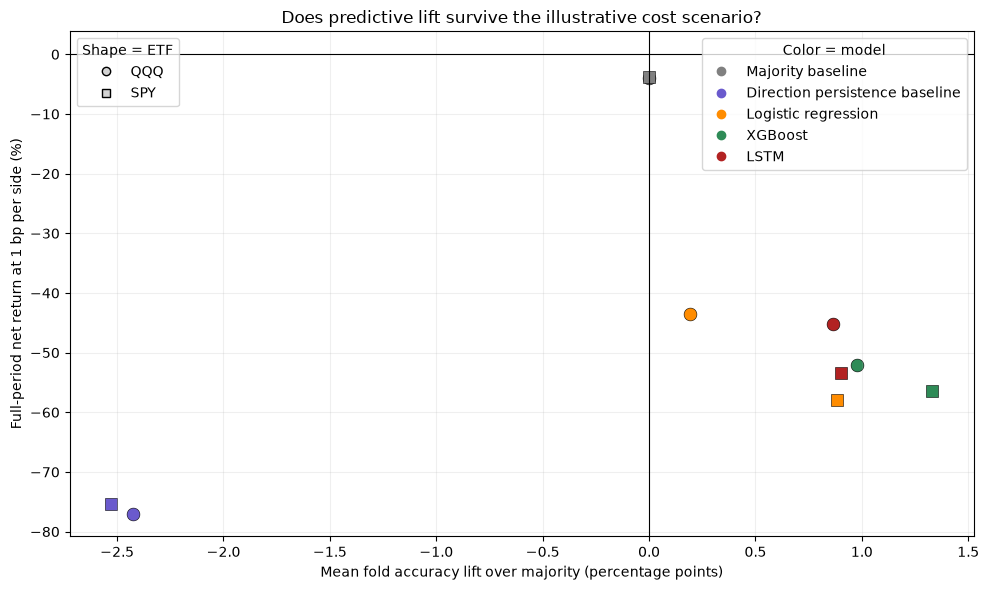

In [11]:
from matplotlib.lines import Line2D

# Color identifies the model; marker shape identifies the ETF.
model_colors = {
    'Majority baseline': 'gray',
    'Direction persistence baseline': 'slateblue',
    'Logistic regression': 'darkorange',
    'XGBoost': 'seagreen',
    'LSTM': 'firebrick',
}
etf_markers = {'QQQ': 'o', 'SPY': 's'}
fig, ax = plt.subplots(figsize=(10, 6))
for row in signal_to_execution.itertuples(index=False):
    ax.scatter(
        row.accuracy_lift_pp,
        row.return_1bp_pct,
        color=model_colors[row.model_predictive],
        marker=etf_markers[row.ETF],
        s=85,
        edgecolor='black',
        linewidth=0.4,
    )

# Separate legends keep the two visual encodings easy to read.
model_handles = [
    Line2D([], [], marker='o', linestyle='none', color=color, label=model)
    for model, color in model_colors.items()
]
etf_handles = [
    Line2D([], [], marker=marker, linestyle='none', markerfacecolor='lightgray',
           markeredgecolor='black', color='black', label=ticker)
    for ticker, marker in etf_markers.items()
]
model_legend = ax.legend(
    handles=model_handles, title='Color = model',
    loc='upper right', frameon=True,
)
ax.add_artist(model_legend)
ax.legend(
    handles=etf_handles, title='Shape = ETF',
    loc='upper left', frameon=True,
)

# The zero lines mark positive versus negative lift and return.
ax.axhline(0, color='black', linewidth=0.8)
ax.axvline(0, color='black', linewidth=0.8)
ax.set_xlabel('Mean fold accuracy lift over majority (percentage points)')
ax.set_ylabel('Full-period net return at 1 bp per side (%)')
ax.set_title('Does predictive lift survive the illustrative cost scenario?')
ax.grid(alpha=0.2)
fig.tight_layout()
plt.show()